# German Credit Risk: Exploration, Drivers, and Validation

This notebook analyzes the Kaggle **Weka German Credit** dataset. Each row is an applicant; `class` labels credit risk as `good` or `bad` (300 bad / 700 good). The 20 predictors include 13 categorical and 7 numeric fields. This is a small, historical teaching dataset, not a production underwriting model. Its `bad` label is treated as the positive class throughout.

The accompanying Chapter 2 material emphasizes binary default outcomes, GLM/logistic baselines, machine-learning challengers, and validation. Accordingly, this notebook uses a logistic-regression baseline and a random-forest challenger, with preprocessing fitted inside pipelines.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score)
from sklearn.inspection import permutation_importance
RANDOM_STATE=42
sns.set_theme(style="whitegrid")

## Load and validate data
The CSV is included alongside this notebook. For a fresh run without the local file, it can be downloaded from the public Kaggle dataset endpoint. Kaggle may revise the archive, so shape and target checks below act as safeguards.

In [2]:
DATA_PATH=Path("credit-g.csv")
if not DATA_PATH.exists():
    import requests, zipfile, io
    url="https://www.kaggle.com/api/v1/datasets/download/btolar1/weka-german-credit"
    response=requests.get(url, timeout=60); response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        csv_name=next(n for n in z.namelist() if n.lower().endswith('.csv'))
        DATA_PATH.write_bytes(z.read(csv_name))
df=pd.read_csv(DATA_PATH)
df.columns=df.columns.str.strip()
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print("Shape:", df.shape)
print("Target counts:\n", df["class"].value_counts())
assert df.shape[0] == 1000 and "class" in df.columns
assert set(df["class"].unique()) == {"good", "bad"}
df.info()

Shape: (1000, 21)
Target counts:
 class
good    700
bad     300
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   checking_status         1000 non-null   str  
 1   duration                1000 non-null   int64
 2   credit_history          1000 non-null   str  
 3   purpose                 1000 non-null   str  
 4   credit_amount           1000 non-null   int64
 5   savings_status          1000 non-null   str  
 6   employment              1000 non-null   str  
 7   installment_commitment  1000 non-null   int64
 8   personal_status         1000 non-null   str  
 9   other_parties           1000 non-null   str  
 10  residence_since         1000 non-null   int64
 11  property_magnitude      1000 non-null   str  
 12  age                     1000 non-null   int64
 13  other_payment_plans     1000 non-null   str  

## Data preparation and exploration
Check duplicate rows, missingness, type balance, class imbalance, and summary statistics. Numeric codes such as `installment_commitment` are retained as numeric ordinal values because they represent ordered categories.

Exact duplicate rows: 0
Missing values (largest first):
 checking_status        0
property_magnitude     0
foreign_worker         0
own_telephone          0
num_dependents         0
job                    0
existing_credits       0
housing                0
other_payment_plans    0
age                    0
dtype: int64

Unique values per field:
 class                       2
own_telephone               2
num_dependents              2
foreign_worker              2
housing                     3
other_payment_plans         3
other_parties               3
job                         4
existing_credits            4
property_magnitude          4
checking_status             4
installment_commitment      4
personal_status             4
residence_since             4
employment                  5
savings_status              5
credit_history              5
purpose                    10
duration                   33
age                        53
credit_amount             921
dtype: int64

Numeric s

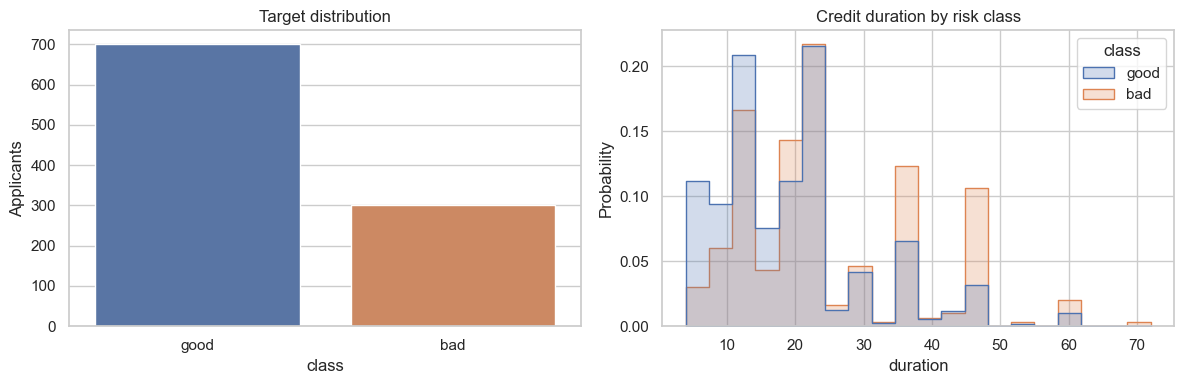

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing values (largest first):\n", df.isna().sum().sort_values(ascending=False).head(10))
print("\nUnique values per field:\n", df.nunique().sort_values())
print("\nNumeric summary:\n", df.describe().T)
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=df,x="class",order=["good","bad"],ax=ax[0],hue="class",legend=False)
ax[0].set_title("Target distribution"); ax[0].set_ylabel("Applicants")
sns.histplot(data=df,x="duration",hue="class",bins=20,element="step",stat="probability",common_norm=False,ax=ax[1])
ax[1].set_title("Credit duration by risk class")
plt.tight_layout()

Categorical predictors: 13; numeric predictors: 7


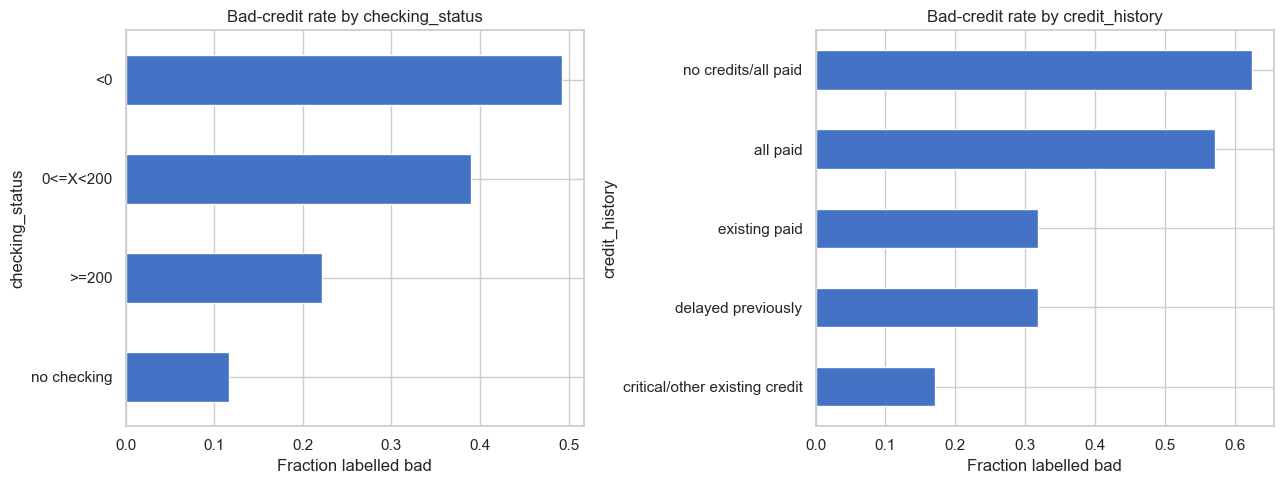

In [5]:
cat_cols=df.drop(columns="class").select_dtypes(include="object").columns.tolist()
num_cols=df.drop(columns="class").select_dtypes(exclude="object").columns.tolist()
print(f"Categorical predictors: {len(cat_cols)}; numeric predictors: {len(num_cols)}")
fig,axes=plt.subplots(1,2,figsize=(13,5))
for a,col in zip(axes,["checking_status","credit_history"]):
    rate=(df.assign(bad=(df["class"]=="bad").astype(int)).groupby(col,observed=True)["bad"].mean().sort_values())
    rate.plot(kind="barh",ax=a,color="#4472C4"); a.set_title(f"Bad-credit rate by {col}"); a.set_xlabel("Fraction labelled bad")
plt.tight_layout()

## Modeling and validation
Use a stratified 80/20 holdout. Compare logistic regression with a class-weighted random forest. Five-fold stratified cross-validation is run on the training partition only. Report ROC-AUC, average precision (PR-AUC summary), balanced accuracy, and Brier score; threshold-based metrics use the default 0.5 cutoff. Because missing values are absent in this dataset, median/mode imputers are included as robust pipeline steps. One-hot encoding is learned within each fold.

In [6]:
X=df.drop(columns="class"); y=(df["class"]=="bad").astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=RANDOM_STATE)
num_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
cat_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])
prep=ColumnTransformer([("numeric",num_pipe,num_cols),("categorical",cat_pipe,cat_cols)])
models={
 "Logistic regression":Pipeline([("prep",prep),("model",LogisticRegression(max_iter=2000,class_weight="balanced",random_state=RANDOM_STATE))]),
 "Random forest":Pipeline([("prep",prep),("model",RandomForestClassifier(n_estimators=500,min_samples_leaf=3,class_weight="balanced",random_state=RANDOM_STATE,n_jobs=-1))])}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
scoring={"roc_auc":"roc_auc","average_precision":"average_precision","balanced_accuracy":"balanced_accuracy","neg_brier":"neg_brier_score"}
rows=[]
for name,model in models.items():
    res=cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    rows.append({"Model":name,**{k.replace("test_",""):v.mean() for k,v in res.items() if k.startswith("test_")},"CV AUC SD":res["test_roc_auc"].std()})
cv_results=pd.DataFrame(rows).sort_values("roc_auc",ascending=False)
cv_results

,Model,roc_auc,average_precision,balanced_accuracy,neg_brier,CV AUC SD
1,Random forest,0.797359,0.637988,0.707143,-0.170057,0.039054
0,Logistic regression,0.768676,0.589288,0.688988,-0.196124,0.052978


Selected by mean training-CV ROC-AUC: Random forest
Holdout ROC-AUC: 0.801
Holdout average precision: 0.65
Holdout balanced accuracy: 0.702
Holdout Brier score: 0.169
              precision    recall  f1-score   support

        good       0.82      0.82      0.82       140
         bad       0.58      0.58      0.58        60

    accuracy                           0.75       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.75      0.75      0.75       200



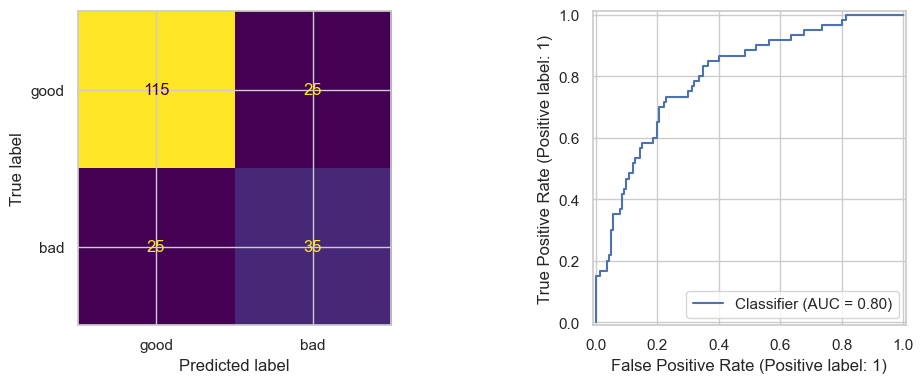

In [7]:
best_name=cv_results.iloc[0]["Model"]
best=models[best_name].fit(X_train,y_train)
proba=best.predict_proba(X_test)[:,1]; pred=(proba>=0.5).astype(int)
print("Selected by mean training-CV ROC-AUC:",best_name)
print("Holdout ROC-AUC:",round(roc_auc_score(y_test,proba),3))
print("Holdout average precision:",round(average_precision_score(y_test,proba),3))
print("Holdout balanced accuracy:",round(balanced_accuracy_score(y_test,pred),3))
print("Holdout Brier score:",round(brier_score_loss(y_test,proba),3))
print(classification_report(y_test,pred,target_names=["good","bad"],zero_division=0))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["good","bad"],ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,proba,ax=ax[1]); plt.tight_layout()

## Three most important original features
Estimate permutation importance on the held-out set using ROC-AUC as the score. To avoid confusing one-hot dummy columns with original variables, permutation is applied to raw input columns and the fitted pipeline re-encodes them. This is a predictive-importance ranking, not a causal explanation; correlated predictors can share or mask importance. Rank stability should be interpreted cautiously because the test set has only 200 applicants.

In [8]:
perm=permutation_importance(best,X_test,y_test,scoring="roc_auc",n_repeats=30,random_state=RANDOM_STATE,n_jobs=-1)
importance=pd.DataFrame({"Feature":X_test.columns,"Mean AUC decrease":perm.importances_mean,"Std":perm.importances_std}).sort_values("Mean AUC decrease",ascending=False)
importance.head(10)

,Feature,Mean AUC decrease,Std
0,checking_status,0.132091,0.035742
1,duration,0.017373,0.009863
4,credit_amount,0.015520,0.007151
3,purpose,0.013052,0.005549
5,savings_status,0.011933,0.013127
2,credit_history,0.011087,0.009957
9,other_parties,0.009778,0.003259
12,age,0.007790,0.003320
18,own_telephone,0.007111,0.003488
16,job,0.005893,0.003172


Top three predictive features:
1. checking_status: mean ROC-AUC decrease 0.1321 (SD 0.0357)
2. duration: mean ROC-AUC decrease 0.0174 (SD 0.0099)
3. credit_amount: mean ROC-AUC decrease 0.0155 (SD 0.0072)


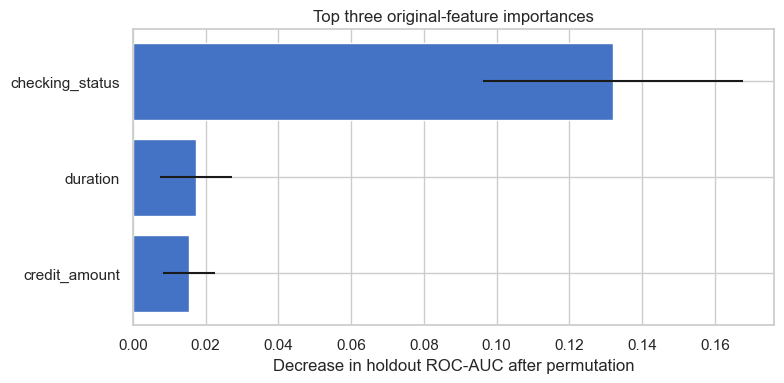

In [9]:
top3=importance.head(3).sort_values("Mean AUC decrease")
print("Top three predictive features:")
for i,r in enumerate(importance.head(3).itertuples(index=False),1):
    print(f"{i}. {r.Feature}: mean ROC-AUC decrease {r[1]:.4f} (SD {r.Std:.4f})")
plt.figure(figsize=(8,4)); plt.barh(top3["Feature"],top3["Mean AUC decrease"],xerr=top3["Std"],color="#4472C4")
plt.xlabel("Decrease in holdout ROC-AUC after permutation"); plt.title("Top three original-feature importances"); plt.tight_layout()

## Interpretation and limitations
The three fields printed above are the dataset-specific leading predictive drivers under this split and selected model. Their ranking is descriptive, not causal. The data are small, old, and contain no time dimension; validation here estimates performance on a random sample from the same source, not future-period or population-shift performance. Credit outcomes are imbalanced (70% good, 30% bad), so accuracy alone would be misleading. A production decision would require out-of-time validation, calibration and threshold/cost analysis, fairness review, monitoring, and documented governance. This exercise is educational and is not suitable for making real lending decisions.

## References
- Dataset: [Kaggle — Weka German Credit](https://www.kaggle.com/datasets/btolar1/weka-german-credit)
- Background supplied with the task: Tiziano Bellini, *IFRS 9 and CECL Credit Risk Modelling and Validation*, Chapter 2 (one-year PD, logistic/GLM models, model validation).